In [12]:
# ===== 0. PENGATURAN =====
SUMBER   = "csv"
PROJECT  = "portofolio-procurement"
DATASET  = "porto_proc"
LOCATION = "asia-southeast2"
CSV_DIR  = "csv"

CUTOFF   = "2026-10-15"
THR_EKSPOSUR, THR_FOLLOWUP, THR_STALE, TOL_PAJAK, Z_OUTLIER = 5_000_000, 14, 14, 1, 3
GRACE    = 1
BOBOT    = dict(kirim=0.40, tagihan=0.30, harga=0.20, fisik=0.10)

In [13]:
# ===== 1. MUAT DATA =====
import os, zipfile, numpy as np, pandas as pd
from scipy import stats as sps
import matplotlib.pyplot as plt
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 200

TABEL = ["supplier","item","param_tolerance","po_line","gr_line","inv_line"]
DATES = {"po_line":["po_date","tgl_kirim_diharapkan"],"gr_line":["gr_date"],"inv_line":["inv_date","tgl_input"]}

if SUMBER == "csv":
    if not os.path.exists(os.path.join(CSV_DIR,"po_line.csv")):
        try:
            from google.colab import files               # hanya ada di Colab
            up = files.upload()                           # pilih data_csv.zip
            for n in up:
                if n.endswith(".zip"): zipfile.ZipFile(n).extractall(".")
        except ImportError:
            raise FileNotFoundError
    if not os.path.exists(os.path.join(CSV_DIR,"po_line.csv")) and os.path.exists("csv/csv/po_line.csv"): CSV_DIR = "csv/csv"
    T = {t: pd.read_csv(f"{CSV_DIR}/{t}.csv", parse_dates=DATES.get(t,[])) for t in TABEL}
else:
    from google.colab import auth; auth.authenticate_user()
    from google.cloud import bigquery
    bq = bigquery.Client(project=PROJECT, location=LOCATION)

    def _samakan_dtype(df):
        for c in df.columns:
            if str(df[c].dtype) in ("Int64", "Float64"):
                df[c] = df[c].astype("float64") if df[c].isna().any() else df[c].astype("int64")
        return df

    T = {t: _samakan_dtype(bq.query(f"SELECT * FROM `{PROJECT}.{DATASET}.{t}`")
                             .to_dataframe(create_bqstorage_client=False)) for t in TABEL}
    for t,cols in DATES.items():
        for c in cols: T[t][c] = pd.to_datetime(T[t][c])

sup, itm, par, po, gr, inv = (T[k] for k in ["supplier","item","param_tolerance","po_line","gr_line","inv_line"])
CUT = pd.Timestamp(CUTOFF)
print({k: len(v) for k,v in T.items()})

{'supplier': 9, 'item': 16, 'param_tolerance': 4, 'po_line': 112, 'gr_line': 116, 'inv_line': 110}


Analisis 1 – Three-Way Match

In [14]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k/n; d = 1 + z*z/n
    c = p + z*z/(2*n); h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return ((c-h)/d, (c+h)/d)

def three_way():
    m = (po.merge(sup[["supplier_id","supplier_name","tarif_ppn"]], on="supplier_id")
           .merge(itm[["item_id","item_name","kategori"]], on="item_id")
           .merge(par, on="kategori"))
    g = gr.groupby("po_line_id").agg(qty_gr=("qty_diterima","sum"), ekor_gr=("ekor_diterima","sum"),
                                     n_gr=("gr_line_id","count"), last_gr=("gr_date","max"))
    i2 = inv.copy(); i2["k"] = i2.groupby(["supplier_id","inv_no","po_line_id"]).inv_line_id.transform("count")
    i = i2.groupby("po_line_id").agg(qty_inv=("qty_faktur","sum"), inv_net=("jumlah_faktur","sum"),
                                     inv_tax=("ppn_faktur","sum"), n_inv=("inv_line_id","count"),
                                     dup=("k", lambda x: int((x>1).any())))
    m = m.merge(g, on="po_line_id", how="left").merge(i, on="po_line_id", how="left")
    for c in ["qty_gr","ekor_gr","n_gr","qty_inv","inv_net","inv_tax","n_inv","dup"]: m[c] = m[c].fillna(0)
    m["harga_inv"] = np.where(m.qty_inv>0, m.inv_net/m.qty_inv.replace(0,np.nan), np.nan)
    m["v_gr"]  = np.where(m.qty_gr>0, (m.qty_gr-m.qty_po)/m.qty_po, np.nan)
    m["v_inv"] = np.where((m.qty_gr>0)&(m.qty_inv>0), (m.qty_inv-m.qty_gr)/m.qty_gr.replace(0,np.nan), np.nan)
    m["v_hrg"] = np.where(m.qty_inv>0, (m.harga_inv-m.harga_po)/m.harga_po, np.nan)
    m["f_dup"]   = m.dup>0
    m["f_nogr"]  = (m.qty_inv>0)&(m.qty_gr==0)
    m["f_noinv"] = (m.qty_gr>0)&(m.qty_inv==0)
    m["f_open"]  = (m.qty_gr==0)&(m.qty_inv==0)
    m["f_qgr"]   = (m.qty_gr>0)&((m.v_gr.abs()>m.tol_gr_vs_po)|(m.ekor_po.notna()&(m.ekor_gr!=m.ekor_po.fillna(0))))
    m["f_qinv"]  = (m.qty_gr>0)&(m.qty_inv>0)&(m.v_inv.abs()>m.tol_inv_vs_gr)
    m["f_hrg"]   = (m.qty_inv>0)&(m.v_hrg.abs()>m.tol_harga)
    m["pajak_seharusnya"] = (m.inv_net*m.tarif_ppn).round(0)
    m["f_tax"]   = (m.qty_inv>0)&((m.inv_tax-m.pajak_seharusnya).abs()>TOL_PAJAK)
    m["payable"] = np.where((m.qty_gr>0)&(m.qty_inv>0), np.minimum(m.qty_gr,m.qty_inv)*m.harga_po, 0)
    m["exp_tax"] = np.where(m.qty_inv>0, m.inv_tax-m.pajak_seharusnya, 0)
    m["eksposur"] = np.where(m.inv_net>0, np.maximum(0,m.inv_net-m.payable)+np.maximum(0,m.exp_tax), 0)
    def st(r):
        if r.f_dup:   return "DUPLIKAT INVOICE"
        if r.f_nogr:  return "INVOICE TANPA GR"
        if r.f_open:  return "PO BELUM DITERIMA"
        if r.f_noinv: return "GR BELUM DIFAKTURKAN"
        if r.f_hrg:   return "SELISIH HARGA"
        if r.f_qinv:  return "SELISIH QTY INVOICE-GR"
        if r.f_qgr:   return "SELISIH QTY GR-PO"
        if r.f_tax:   return "PAJAK TIDAK SESUAI"
        return "MATCH"
    m["status"] = m.apply(st, axis=1)
    return m

m1 = three_way()
ring = m1.groupby("status").agg(n_baris=("po_line_id","count"), eksposur_rp=("eksposur","sum")).sort_values("eksposur_rp", ascending=False)
ring["pct_baris"] = 100*ring.n_baris/ring.n_baris.sum()
display(ring) if "display" in globals() else print(ring)
lengkap = m1[(m1.qty_gr>0)&(m1.qty_inv>0)]
print(f"First-pass match rate: {(lengkap.status=='MATCH').sum()}/{len(lengkap)} = {100*(lengkap.status=='MATCH').mean():.1f}%")
print(f"Total eksposur: Rp {m1.eksposur.sum():,.0f}")

                        n_baris    eksposur_rp  pct_baris
status                                                   
DUPLIKAT INVOICE              3 303,957,200.00       2.68
SELISIH QTY INVOICE-GR       15  40,638,400.00      13.39
INVOICE TANPA GR              3  39,178,200.00       2.68
MATCH                        69  10,371,250.00      61.61
SELISIH HARGA                 8   4,342,880.00       7.14
SELISIH QTY GR-PO             4     742,000.00       3.57
PAJAK TIDAK SESUAI            2     357,858.00       1.79
GR BELUM DIFAKTURKAN          6           0.00       5.36
PO BELUM DITERIMA             2           0.00       1.79
First-pass match rate: 69/101 = 68.3%
Total eksposur: Rp 399,587,788


In [15]:
# Match rate per kategori + interval Wilson 95%
rows = []
for kat, d in lengkap.groupby("kategori"):
    k, n = int((d.status=="MATCH").sum()), len(d); lo, hi = wilson(k, n)
    rows.append(dict(kategori=kat, n=n, match=k, match_pct=100*k/n, ci_bawah=100*lo, ci_atas=100*hi))
print(pd.DataFrame(rows).sort_values("match_pct").to_string(index=False))

# Uji bias per supplier: selisih qty faktur vs GR (tanpa faktur ganda)
b = m1[(~m1.f_dup)&m1.v_inv.notna()]
rows = []
for sid, d in b.groupby("supplier_id"):
    x = d.v_inv.values; n = len(x); tol = d.tol_inv_vs_gr.iloc[0]
    if n > 2 and x.std(ddof=1) > 0:
        t0 = sps.ttest_1samp(x, 0.0)
        tt = sps.ttest_1samp(x, tol, alternative="greater")   # H1: rata-rata > toleransi
        rows.append(dict(supplier=sid, n=n, mean_pct=100*x.mean(), sd_pct=100*x.std(ddof=1), tol_pct=100*tol,
                         t_vs_0=t0.statistic, p_vs_0=t0.pvalue, t_vs_tol=tt.statistic, p_lebih_dari_tol=tt.pvalue))
print(); print(pd.DataFrame(rows).sort_values("mean_pct", ascending=False).round(4).to_string(index=False))

# Outlier z-score terhadap kategorinya
g = b.groupby("kategori").v_inv.agg(["mean","std"])
b = b.join(g, on="kategori"); b["z"] = (b.v_inv-b["mean"])/b["std"]
print(); print(b[b.z.abs()>Z_OUTLIER][["po_line_id","supplier_id","kategori","v_inv","z"]].sort_values("z", key=abs, ascending=False).round(3).to_string(index=False))

      kategori  n  match  match_pct  ci_bawah  ci_atas
  Bakalan Sapi 33     17      51.52     35.22    67.50
  Pakan Kering 32     23      71.88     54.63    84.44
   Pakan Segar 18     14      77.78     54.78    91.00
Obat & Vitamin 18     15      83.33     60.78    94.16

supplier  n  mean_pct  sd_pct  tol_pct  t_vs_0  p_vs_0  t_vs_tol  p_lebih_dari_tol
     S03 12      4.12    2.94     2.00    4.85    0.00      2.49              0.01
     S08 13      1.92    6.93     0.00    1.00    0.34      1.00              0.17
     S06 12      0.95    1.18     3.00    2.79    0.02     -6.04              1.00
     S04 16      0.86    3.44     1.00    1.00    0.33     -0.16              0.56
     S01  9      0.78    0.54     2.00    4.37    0.00     -6.83              1.00
     S05 15      0.77    2.96     1.00    1.00    0.33     -0.31              0.62
     S02 10      0.57    0.51     2.00    3.49    0.01     -8.84              1.00

    po_line_id supplier_id       kategori  v_inv    z
PO-20

    po_line_id               supplier_name                 status       eksposur  aging_hari prioritas
PO-2026-0062-1      UD Berkah Sapi Lestari       DUPLIKAT INVOICE 153,496,000.00         NaN    TINGGI
PO-2026-0064-2      UD Berkah Sapi Lestari       DUPLIKAT INVOICE 123,540,000.00         NaN    TINGGI
PO-2026-0050-2     PT Agro Pakan Nusantara       INVOICE TANPA GR  27,722,250.00         NaN    TINGGI
PO-2026-0054-1     PT Agro Pakan Nusantara       DUPLIKAT INVOICE  26,921,200.00         NaN    TINGGI
PO-2026-0040-1        UD Sumber Pakan Jaya       INVOICE TANPA GR  10,159,200.00         NaN    TINGGI
PO-2026-0029-1 H. Sulaiman (Pedagang Sapi) SELISIH QTY INVOICE-GR   6,993,000.00         NaN    TINGGI
PO-2026-0020-2 H. Sulaiman (Pedagang Sapi) SELISIH QTY INVOICE-GR   6,780,000.00         NaN    TINGGI
PO-2026-0032-1     PT Agro Pakan Nusantara       INVOICE TANPA GR   1,296,750.00         NaN    TINGGI
PO-2026-0070-1 H. Sulaiman (Pedagang Sapi) SELISIH QTY INVOICE-GR   4,875

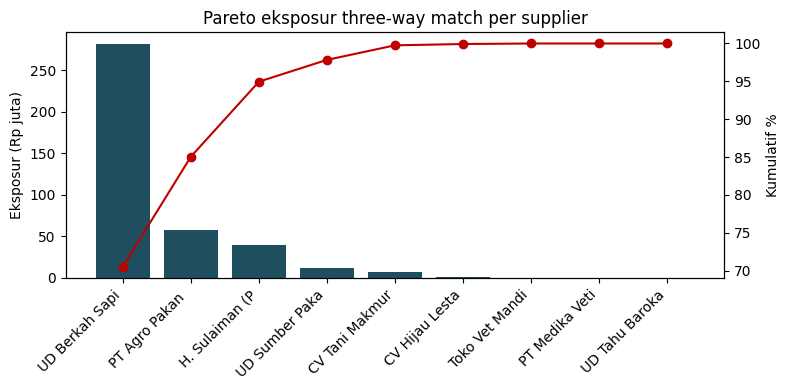

In [16]:
# Antrian tindak lanjut (non-MATCH) dengan prioritas dan aging
q = m1[m1.status!="MATCH"].copy()
q["aging_hari"] = np.where(q.f_noinv, (CUT-q.last_gr).dt.days, np.where(q.f_open, (CUT-q.tgl_kirim_diharapkan).dt.days, np.nan))
def prio(r):
    if r.f_dup or r.f_nogr or r.eksposur >= THR_EKSPOSUR: return "TINGGI"
    if r.f_noinv: return "SEDANG" if r.aging_hari > THR_FOLLOWUP else "RENDAH"
    if r.f_open:  return "SEDANG" if r.aging_hari > THR_STALE else "RENDAH"
    return "SEDANG"
q["prioritas"] = q.apply(prio, axis=1)
q["_o"] = q.prioritas.map({"TINGGI":0,"SEDANG":1,"RENDAH":2})
print(q.sort_values(["_o","eksposur"], ascending=[True,False])[["po_line_id","supplier_name","status","eksposur","aging_hari","prioritas"]].head(15).to_string(index=False))

# Pareto eksposur per supplier
par_s = m1.groupby("supplier_name").eksposur.sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8,4)); ax.bar(range(len(par_s)), par_s.values/1e6, color="#1F4E5F")
ax2 = ax.twinx(); ax2.plot(range(len(par_s)), 100*par_s.cumsum()/par_s.sum(), color="#C00000", marker="o")
ax.set_xticks(range(len(par_s))); ax.set_xticklabels([s[:14] for s in par_s.index], rotation=45, ha="right")
ax.set_ylabel("Eksposur (Rp juta)"); ax2.set_ylabel("Kumulatif %"); ax.set_title("Pareto eksposur three-way match per supplier")
plt.tight_layout(); plt.show()

Analisis 2 – Purchase Price Variance (PPV)

In [17]:
START = pd.Timestamp("2026-04-01")
def ppv():
    m = po.merge(sup[["supplier_id","supplier_name"]], on="supplier_id").merge(
        itm[["item_id","item_name","kategori","harga_acuan"]], on="item_id")
    g = gr.groupby("po_line_id").qty_diterima.sum().rename("qty_gr")
    i = inv.groupby("po_line_id").agg(qty_inv=("qty_faktur","sum"), inv_net=("jumlah_faktur","sum"))
    m = m.merge(g, on="po_line_id", how="left").merge(i, on="po_line_id", how="left").fillna({"qty_gr":0,"qty_inv":0,"inv_net":0})
    m["bulan"] = m.po_date.dt.year*100 + m.po_date.dt.month
    m["std"] = m.harga_acuan
    m["harga_aktual"] = np.where(m.qty_inv>0, m.inv_net/m.qty_inv.replace(0,np.nan), m.harga_po)
    m["p"] = (m.qty_gr>0).astype(int)
    m["q_std"] = m.p*m.qty_gr*m["std"]; m["q_po"] = m.p*m.qty_gr*m.harga_po; m["q_act"] = m.p*m.qty_gr*m.harga_aktual
    cm = m.groupby(["kategori","bulan"]).agg(a=("q_po","sum"), b=("q_std","sum"))
    cm["idx"] = np.where(cm.b>0, cm.a/cm.b, 1.0)
    m = m.merge(cm["idx"].rename("idx_pasar").reset_index(), on=["kategori","bulan"])
    m["efek_pasar"]    = m.p*(m.idx_pasar-1)*m.q_std
    m["efek_supplier"] = m.p*(m.q_po-m.idx_pasar*m.q_std)
    m["efek_faktur"]   = m.p*(m.q_act-m.q_po)
    m["ppv"] = m.q_act-m.q_std
    m["rpi"] = np.where(m.p==1, m.harga_po/(m.idx_pasar*m["std"]), np.nan)   # indeks harga relatif thd pasar
    m["idx_line"] = m.harga_po/m["std"]
    return m.sort_values("po_line_id").reset_index(drop=True), cm

m2, cm = ppv()
kat = m2.groupby("kategori")[["q_std","q_act","ppv","efek_pasar","efek_supplier","efek_faktur"]].sum()
kat["ppv_pct"] = 100*kat.ppv/kat.q_std
print(kat.round(0).assign(ppv_pct=kat.ppv_pct.round(2)).to_string())
print("\nTotal PPV: Rp {:,.0f}  (cek dekomposisi: {:,.0f})".format(m2.ppv.sum(), m2[['efek_pasar','efek_supplier','efek_faktur']].sum().sum()))
print("\nPPV per supplier:"); print(m2.groupby("supplier_name")[["efek_pasar","efek_supplier","efek_faktur","ppv"]].sum().sort_values("ppv", ascending=False).round(0).to_string())

                          q_std            q_act           ppv    efek_pasar  efek_supplier  efek_faktur  ppv_pct
kategori                                                                                                         
Bakalan Sapi   2,987,883,000.00 3,002,556,000.00 14,673,000.00 13,708,000.00           0.00   965,000.00     0.49
Obat & Vitamin    16,310,000.00    16,401,000.00     91,000.00    -21,500.00          -0.00   112,500.00     0.56
Pakan Kering     259,623,900.00   263,755,630.00  4,131,730.00  1,378,350.00          -0.00 2,753,380.00     1.59
Pakan Segar       50,455,450.00    50,642,450.00    187,000.00    187,000.00          -0.00         0.00     0.37

Total PPV: Rp 19,082,730  (cek dekomposisi: 19,082,730)

PPV per supplier:
                               efek_pasar  efek_supplier  efek_faktur           ppv
supplier_name                                                                      
H. Sulaiman (Pedagang Sapi) 18,662,845.00    -774,345.00         0.00 17

bulan           202604  202605  202606  202607  202608  202609
kategori                                                      
Bakalan Sapi      1.03    1.07    1.00    0.99    0.99    1.01
Obat & Vitamin    1.00    0.97    1.09    1.00    0.98    0.98
Pakan Kering      1.00    1.00    1.00    1.00    1.01    1.02
Pakan Segar       1.00    1.00    1.00    1.02    1.00    1.00


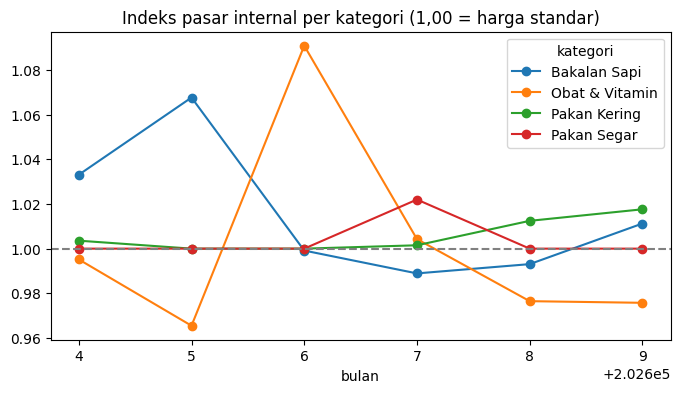


   item  k  N    F  p_value
 BKL-BX  3 14 0.92     0.43
 BKL-LM  2  9 0.96     0.36
OBT-OTC  2  5 3.86     0.14
OBT-VTB  2  7 4.89     0.08

      kategori  n  pct_per_30_hari   r2     t  p_value
  Bakalan Sapi 33            -0.43 0.11 -1.98     0.06
Obat & Vitamin 19            -0.43 0.03 -0.66     0.52
  Pakan Kering 33             0.32 0.40  4.58     0.00
   Pakan Segar 22             0.12 0.02  0.67     0.51

          n     min     max       mean       sd  cv_pct
item_id                                                
OBT-OTC   5   94500  107500 102,000.00 6,422.62    6.30
OBT-VTB   7   74500   85000  78,000.00 4,654.75    5.97
BKL-LM    9   62000   67500  63,666.67 1,620.19    2.54
BKL-BX   14   52000   56500  53,392.86 1,163.19    2.18
BKL-SM    3   62000   64500  63,000.00 1,322.88    2.10
PKN-KON   6    5350    5550   5,425.00    68.92    1.27
PKN-HJN  14     550     575     551.79     6.68    1.21
PKN-MLS   8    3200    3300   3,225.00    37.80    1.17
PKN-BSW   4    2900   

In [18]:
# Indeks pasar bulanan
idx = cm.idx.unstack(); print(idx.round(4).to_string())
idx.T.plot(marker="o", figsize=(8,4), title="Indeks pasar internal per kategori (1,00 = harga standar)"); plt.axhline(1, color="grey", ls="--"); plt.show()

# ANOVA satu arah: apakah supplier berbeda untuk item yang sama? (indeks harga relatif)
rows = []
for it, d in m2[m2.p==1].groupby("item_id"):
    grp = [x.rpi.values for _,x in d.groupby("supplier_id") if len(x)>0]
    if len(grp) >= 2:
        F, p = sps.f_oneway(*grp); rows.append(dict(item=it, k=len(grp), N=len(d), F=F, p_value=p))
print(); print(pd.DataFrame(rows).round(4).to_string(index=False))

# Tren harga per kategori: regresi indeks harga PO/standar terhadap hari sejak 2026-04-01
rows = []
for k_, d in m2[m2.p==1].groupby("kategori"):
    r = sps.linregress((d.po_date-START).dt.days.astype(float), d.idx_line)
    rows.append(dict(kategori=k_, n=len(d), pct_per_30_hari=100*30*r.slope, r2=r.rvalue**2, t=r.slope/r.stderr, p_value=r.pvalue))
print(); print(pd.DataFrame(rows).round(4).to_string(index=False))

# Profil harga per item (CV)
pr = m2[m2.p==1].groupby("item_id").harga_po.agg(n="count", min="min", max="max", mean="mean", sd="std"); pr["cv_pct"] = 100*pr.sd/pr["mean"]
print(); print(pr.sort_values("cv_pct", ascending=False).round(2).to_string())
print(); print(m2[m2.p==1].sort_values("ppv", ascending=False)[["po_line_id","supplier_name","item_name","ppv","efek_pasar","efek_supplier","efek_faktur"]].head(10).round(0).to_string(index=False))

Analisis 3 – OTIF dan Supplier Scorecard

In [19]:
def otif(grace=GRACE):
    m = three_way().copy()
    m["dinilai"] = (~((m.qty_gr==0)&(m.status=="INVOICE TANPA GR"))).astype(int)
    m["hari_telat"] = np.where(m.qty_gr>0, (m.last_gr-m.tgl_kirim_diharapkan).dt.days, (CUT-m.tgl_kirim_diharapkan).dt.days)
    m["ontime"] = ((m.hari_telat<=grace)&(m.qty_gr>0)&(m.dinilai==1)).astype(int)
    m["infull"] = ((m.qty_gr>=m.qty_po*(1-m.tol_gr_vs_po))&(m.ekor_po.isna()|(m.ekor_gr>=m.ekor_po.fillna(0)))
                   &(m.qty_gr>0)&(m.dinilai==1)).astype(int)
    m["otif"] = m.ontime*m.infull
    m["fill"] = np.where(m.dinilai==1, np.minimum(m.qty_gr,m.qty_po), 0)
    m["qpo_d"] = np.where(m.dinilai==1, m.qty_po, 0)
    m["f_telat"] = ((m.hari_telat>grace)&(m.qty_gr>0)&(m.dinilai==1)).astype(int)
    m["telat_hari"] = m.f_telat*m.hari_telat
    m["lead_aktual"] = np.where(m.qty_gr>0, (m.last_gr-m.po_date).dt.days, np.nan)
    m["lead_janji"]  = (m.tgl_kirim_diharapkan-m.po_date).dt.days
    m["has_inv"] = (m.qty_inv>0).astype(int)
    m["complete"] = ((m.qty_gr>0)&(m.qty_inv>0)).astype(int)
    def cause(r):
        if r.dinilai==0: return "Tidak dinilai"
        if r.otif==1: return "OTIF"
        if r.qty_gr==0: return "Belum diterima"
        if r.ontime==0 and r.infull==0: return "Telat & kurang"
        return "Telat" if r.ontime==0 else "Kurang"
    m["penyebab"] = m.apply(cause, axis=1)
    return m

m3 = otif(); d3 = m3[m3.dinilai==1]
n, k = len(d3), int(d3.otif.sum()); lo, hi = wilson(k, n)
print(f"Baris dinilai: {n} (tidak dinilai: {(m3.dinilai==0).sum()})")
print(f"OTIF {100*k/n:.1f}%  (CI 95% {100*lo:.1f}-{100*hi:.1f}%) | tepat waktu {100*d3.ontime.mean():.1f}% | lengkap {100*d3.infull.mean():.1f}%")
print("\nSensitivitas grace:", {g_: round(100*otif(g_).query('dinilai==1').otif.mean(),1) for g_ in (0,1,2,3)})
print("\nPenyebab gagal:", d3[d3.otif==0].penyebab.value_counts().to_dict())
kat3 = d3.groupby("kategori").agg(n=("otif","size"), otif=("otif","sum"), ontime=("ontime","mean"), infull=("infull","mean"))
kat3["otif_pct"] = 100*kat3.otif/kat3.n; print(); print(kat3.round(3).to_string())

Baris dinilai: 109 (tidak dinilai: 3)
OTIF 63.3%  (CI 95% 53.9-71.8%) | tepat waktu 67.9% | lengkap 90.8%

Sensitivitas grace: {0: np.float64(42.2), 1: np.float64(63.3), 2: np.float64(68.8), 3: np.float64(75.2)}

Penyebab gagal: {'Telat': 30, 'Kurang': 5, 'Telat & kurang': 3, 'Belum diterima': 2}

                 n  otif  ontime  infull  otif_pct
kategori                                          
Bakalan Sapi    33    25    0.82    0.88     75.76
Obat & Vitamin  19     9    0.47    0.95     47.37
Pakan Kering    35    20    0.66    0.86     57.14
Pakan Segar     22    15    0.68    1.00     68.18


In [20]:
# ===== SCORECARD =====
def scorecard(d, mfull, w=BOBOT):
    g = d.groupby("supplier_id")
    s = pd.DataFrame({
        "supplier": g.supplier_name.first(), "n": g.size(), "k": g.otif.sum(),
        "ontime": g.ontime.mean(), "infull": g.infull.mean(),
        "fill_rate": g.fill.sum()/g.qpo_d.sum(),
        "tagihan": g.apply(lambda x: (x.status=="MATCH").sum()/max(1,x.complete.sum())),     # akurasi tagihan (Analisis 1)
        "fisik": g.apply(lambda x: np.nan if x.ekor_po.isna().all() else x.ekor_gr.clip(upper=x.ekor_po).sum()/x.ekor_po.sum()),
    })
    # kepatuhan harga: semua baris berfaktur (cek harga tidak butuh GR)
    s["harga"] = mfull.groupby("supplier_id").apply(lambda x: 1 - x.f_hrg.sum()/max(1, x.has_inv.sum()))
    s["kirim"] = s.k/s.n
    def komposit(r, ww):
        parts = [(ww["kirim"], r.kirim), (ww["tagihan"], r.tagihan), (ww["harga"], r.harga)]
        if not np.isnan(r.fisik): parts.append((ww["fisik"], r.fisik))
        return 100*sum(a*b for a,b in parts)/sum(a for a,_ in parts)
    s["skor"] = s.apply(lambda r: komposit(r, w), axis=1)
    s["skor_sama"] = s.apply(lambda r: komposit(r, dict(kirim=1,tagihan=1,harga=1,fisik=1)), axis=1)
    s["peringkat"] = s.skor.rank(ascending=False, method="min").astype(int)
    s["peringkat_sama"] = s.skor_sama.rank(ascending=False, method="min").astype(int)
    s["grade"] = pd.cut(s.skor, [-1,70,80,90,101], labels=["D","C","B","A"], right=False)
    s["n<10"] = np.where(s.n<10, "ya", "")
    return s.sort_values("skor", ascending=False)

sc = scorecard(d3, m3)
print(sc[["supplier","n","k","kirim","ontime","infull","tagihan","harga","fisik","skor","grade","peringkat","peringkat_sama","n<10"]].round(3).to_string())

# Uji binomial satu sisi: apakah OTIF supplier lebih rendah dari rata-rata keseluruhan?
p0 = k/n
bt = pd.DataFrame({"n": sc.n, "k": sc.k, "otif_pct": 100*sc.k/sc.n,
                   "p_value": [sps.binom.cdf(int(a), int(b), p0) for a,b in zip(sc.k, sc.n)]}, index=sc.index)
bt["kesimpulan"] = np.where(bt.p_value<0.05, "lebih rendah (signifikan)", "tidak berbeda signifikan")
print(f"\nUji binomial vs rata-rata {100*p0:.1f}% (P(X<=k)):"); print(bt.round(4).to_string())

                                supplier   n   k  kirim  ontime  infull  tagihan  harga  fisik  skor grade  peringkat  peringkat_sama n<10
supplier_id                                                                                                                               
S02               UD Berkah Sapi Lestari  12  10   0.83    0.83    1.00     0.83   1.00   1.00 88.33     B          1               1     
S07                      UD Tahu Barokah   8   5   0.62    0.62    1.00     1.00   1.00    NaN 83.33     B          2               2   ya
S09                    PT Medika Vetindo   5   3   0.60    0.60    1.00     1.00   1.00    NaN 82.22     B          3               3   ya
S01                CV Tani Makmur Ternak   9   7   0.78    0.89    0.78     0.67   0.89   0.96 78.52     C          4               4   ya
S06                CV Hijau Lestari Tani  14  10   0.71    0.71    1.00     0.67   1.00    NaN 76.19     C          5               5     
S05                 UD Sumb

/tmp/ipykernel_1585/1971416400.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "tagihan": g.apply(lambda x: (x.status=="MATCH").sum()/max(1,x.complete.sum())),     # akurasi tagihan (Analisis 1)
/tmp/ipykernel_1585/1971416400.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "fisik": g.apply(lambda x: np.nan if x.ekor_po.isna().all() else x.ekor_gr.clip(upper=x.ekor_po).sum()/x.ekor_po.sum()),
/tmp/ip

         n   k    p  ucl  lcl
bulan                        
202604  17   8 0.47 0.98 0.28
202605  14   9 0.64 1.00 0.25
202606  23  16 0.70 0.94 0.33
202607  18  13 0.72 0.97 0.29
202608  19  10 0.53 0.96 0.30
202609  17  12 0.71 0.98 0.28
202610   1   1 1.00 1.00 0.00

Keterlambatan: rata-rata 1.40 hari, SD 1.97
{'<=0': 51, '1': 23, '2': 7, '3': 7, '4-5': 17, '>=6': 2}

      kategori  n  janji  aktual  selisih   sd    t  p_value  lead_disarankan
  Bakalan Sapi 33   3.00    3.91     0.91 2.04 2.56     0.02             6.00
Obat & Vitamin 19   3.00    5.37     2.37 1.57 6.57     0.00             7.00
  Pakan Kering 33   2.00    3.52     1.52 2.24 3.89     0.00             6.00
   Pakan Segar 22   1.00    2.14     1.14 1.49 3.58     0.00             4.00


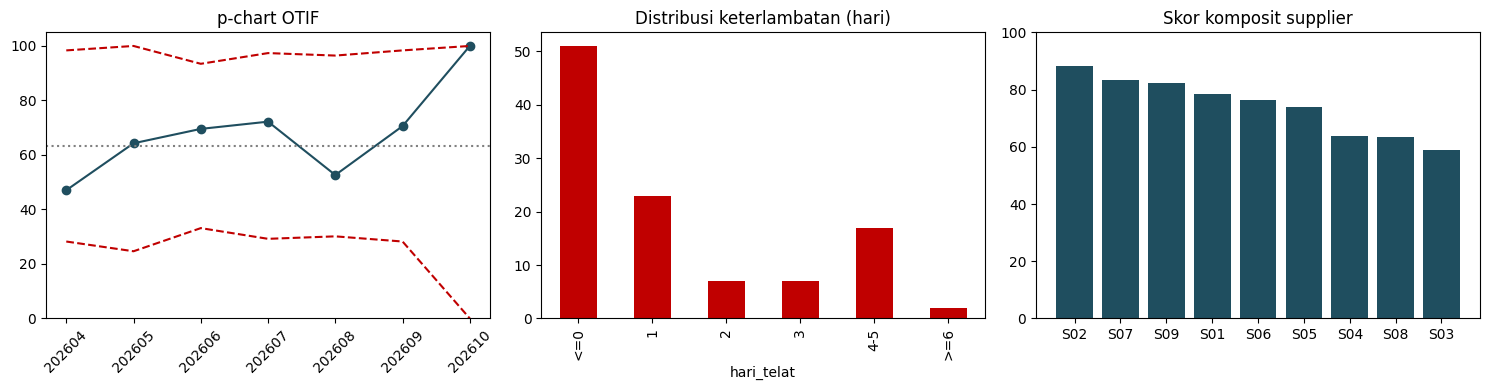

In [21]:
# p-chart OTIF per bulan jatuh tempo (batas 3 sigma)
d3 = d3.assign(bulan=d3.tgl_kirim_diharapkan.dt.year*100+d3.tgl_kirim_diharapkan.dt.month)
pc = d3.groupby("bulan").agg(n=("otif","size"), k=("otif","sum")); pc["p"] = pc.k/pc.n
pc["ucl"] = np.minimum(1, p0+3*np.sqrt(p0*(1-p0)/pc.n)); pc["lcl"] = np.maximum(0, p0-3*np.sqrt(p0*(1-p0)/pc.n))
print(pc.round(3).to_string())

# Distribusi keterlambatan, lead time janji vs aktual (uji-t), lead time disarankan
dl = d3[d3.qty_gr>0]
print("\nKeterlambatan: rata-rata {:.2f} hari, SD {:.2f}".format(dl.hari_telat.mean(), dl.hari_telat.std()))
bins = pd.cut(dl.hari_telat, [-99,0,1,2,3,5,999], labels=["<=0","1","2","3","4-5",">=6"]); print(bins.value_counts().sort_index().to_dict())
rows = []
for kt, x in dl.groupby("kategori"):
    delta = x.hari_telat.values; t = sps.ttest_1samp(delta, 0)
    rows.append(dict(kategori=kt, n=len(x), janji=x.lead_janji.mean(), aktual=x.lead_aktual.mean(), selisih=delta.mean(),
                     sd=delta.std(ddof=1), t=t.statistic, p_value=t.pvalue,
                     lead_disarankan=x.lead_janji.mean()+np.ceil(delta.mean()+0.84*delta.std(ddof=1))))
print(); print(pd.DataFrame(rows).round(4).to_string(index=False))

# Grafik
fig, ax = plt.subplots(1, 3, figsize=(15,4))
ax[0].plot(pc.index.astype(str), 100*pc.p, marker="o", color="#1F4E5F", label="OTIF bulanan")
ax[0].plot(pc.index.astype(str), 100*pc.ucl, "--", color="#C00000"); ax[0].plot(pc.index.astype(str), 100*pc.lcl, "--", color="#C00000")
ax[0].axhline(100*p0, color="grey", ls=":"); ax[0].set_title("p-chart OTIF"); ax[0].set_ylim(0,105); ax[0].tick_params(axis="x", rotation=45)
bins.value_counts().sort_index().plot.bar(ax=ax[1], color="#C00000"); ax[1].set_title("Distribusi keterlambatan (hari)")
ax[2].bar(sc.index, sc.skor, color="#1F4E5F"); ax[2].set_ylim(0,100); ax[2].set_title("Skor komposit supplier")
plt.tight_layout(); plt.show()